# 07 Document extraction

**The question.** Can BidLens read a real Caltrans bid package and pull out what an estimator prices or plans around (working days and damages, lane closure hours, environmental windows, hazardous materials, submittals, payment terms), each with the page it came from, using only free models running on this computer?

**What we did.**
- **The package:** Caltrans contract **04-0W0504** (trash capture devices, maintenance vehicle pullouts, guardrail, erosion control and lighting in Alameda and Contra Costa counties; engineer's estimate $22.7M; bids opened 17 September 2026). It has already been bid, so the results are public and the draft can be checked.
- **Parsing**: the special provisions, three addenda, the bid forms and the information handout are split into page-bounded passages, so every citation points to exactly one page and section. The bid item list, with the addenda applied, matches Caltrans' bid summary exactly: **118 items**, no differences in codes, units or quantities.
- **Reading**: for each of 10 topics, the passages most likely to answer it are found and two open-weight models, **qwen3:8b** and **llama3.1:8b**, answer a checklist of estimator questions through [Ollama](https://ollama.com). Every finding must quote its passage word for word, or it is rejected. Simple facts (dates, working days, dollar amounts) are also read by plain pattern rules, and the 78 lane closure charts are rebuilt from the page layout by code, with no model. Documents never leave the machine and nothing is paid for.
- **Scoring**: **89 gold facts** an estimator needs were written down before any model output was opened, and every finding was judged blind (run hidden).

**What we found.**
- The default run (**both models plus the pattern rules, merged**) found **66 of the 89 facts (74.2%)**; **76.9%** of its findings are correct and **86.4%** cite a page that supports them. F1, the balance of the two: **75.5%**, up from 61.5% for the best single model in round 1. It takes about an hour on a Mac with 16 GB of memory.
- **Where it falls short:** traffic and closure questions (46% of facts found), hazardous materials (71%) and payment terms (70%). About 1 finding in 4 needs correcting, so the app always shows the quote and the page.
- **Caveat:** the gold facts, the judging and the checklist questions were written by Claude, the AI assistant that built BidLens, not by a human estimator. A human review is still open, and the checklist's gain may be somewhat optimistic.
- **End to end:** on this package the BidLens draft total is **$14.54M**, **3% above** the actual low bid of $14.09M; the engineer's estimate ($22.72M) was 61% above it.

The full reports: [`outputs/16_bid_package/`](../outputs/16_bid_package/README.md) to [`outputs/21_app/`](../outputs/21_app/README.md).

## Setup

This loads the project's own code (`src/bidlens/analysis/stages.py`), which reads the results each stage already saved in `outputs/`. Nothing is recomputed here, so the notebook runs in seconds on a fresh copy of the repository, with no database and no model downloads.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
import pandas as pd

from bidlens.analysis import stages as s

pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.max_open_warning"] = 0

## The documents

Each row is one PDF of the package. *Passages* are the page-bounded pieces the models read. The plans are drawings without text and are not read in v1; pages without text are listed, not guessed at.

In [2]:
docs = s.documents()
docs[["Document", "Pages", "Pages without text", "Passages"]]

,Document,Pages,Pages without text,Passages
0,Information Handout (materials and site reports),673,23,1243
1,Addendum No. 1,1,0,2
2,Addendum No. 2,3,0,4
3,Addendum No. 3,1,0,2
4,Forms for bid,3,2,1
5,Notice to Bidders and Special Provisions (includes the bid item list),124,4,236


The bid item list parsed from the special provisions and the addenda, checked against Caltrans' bid summary for this contract. Empty lists mean no differences.

In [3]:
s.bid_item_check()

{'parsed_items': 118,
 'bid_summary_items': 118,
 'bid_summary_deleted_placeholders': ['0026', '0118'],
 'only_in_parsed': [],
 'only_in_summary': [],
 'code_mismatches': [],
 'unit_mismatches': [],
 'quantity_mismatches': []}

## How well each run reads the package

*Precision* is the share of findings that are correct. *Recall* is the share of the 89 gold facts found. *F1* balances the two. Round 1 asked each model for an open list of facts; round 2 asked a checklist of estimator questions and added the pattern rules. The models and the patterns find different facts, so combining them gives the best recall at little cost in precision.

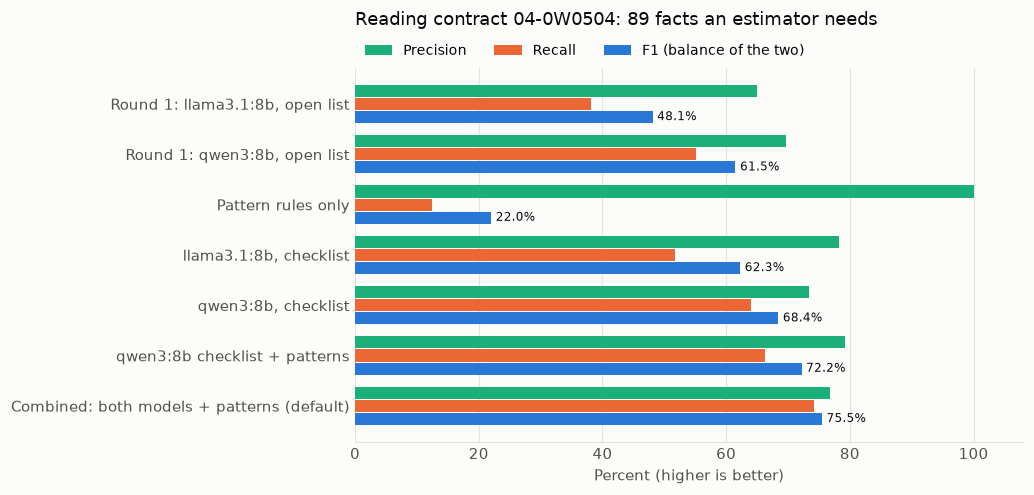

,Run,Findings,Precision,Gold facts found (of 89),Recall,F1,Citation accuracy,Minutes
0,"Round 1: llama3.1:8b, open list",97,64.9%,34,38.2%,48.1%,87.6%,45
1,"Round 1: qwen3:8b, open list",155,69.7%,49,55.1%,61.5%,80.6%,59
2,"qwen3:8b, checklist",98,73.5%,57,64.0%,68.4%,80.6%,32
3,"llama3.1:8b, checklist",83,78.3%,46,51.7%,62.3%,88.0%,27
4,Pattern rules only,19,100.0%,11,12.4%,22.0%,100.0%,0
5,Combined: both models + patterns (default),147,76.9%,66,74.2%,75.5%,86.4%,60
6,qwen3:8b checklist + patterns,106,79.2%,59,66.3%,72.2%,85.8%,32


In [4]:
metrics = s.extraction_metrics()
fig = s.chart_extraction(metrics)
s.save(fig, "extraction_runs", s.S20)
plt.show()
s.extraction_table(metrics)

## By topic

The share of gold facts found in each topic, round 1 (best single model) against the default run. Bid requirements, time and damages, and scope are now read well. Traffic stays the weakest: much of it sits in the closure charts, which are read by code into their own table (shown in the app and the workbook) and are not counted here. Two topics did not improve: environmental stayed at 8 of 9 facts, and utilities fell from 3 of 3 to 2 of 3.

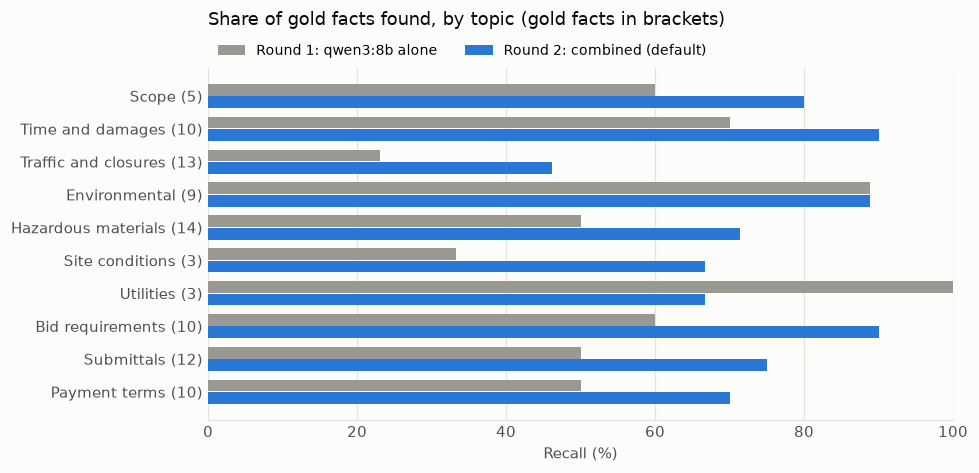

In [5]:
fig = s.chart_recall_by_topic(s.recall_by_topic())
s.save(fig, "recall_by_topic", s.S20)
plt.show()

## What findings look like

A few findings of the default run that were judged correct, with their citations. Pattern-rule findings are exact by construction; model findings are paraphrases, checked against their quoted passage. Phone numbers and email addresses are masked everywhere in the outputs.

In [6]:
s.example_findings()

,Topic,Found by,Finding,Document,PDF page,Section
0,Scope,pattern rule,"The engineer's estimated cost of the project is $22,900,000.",Notice to Bidders and Special Provisions,13,
1,Time and damages,pattern rule,Complete the work within 600 working days.,Notice to Bidders and Special Provisions,13,
2,Time and damages,pattern rule,Start job site activities within 55 days after receiving notice that the Contract has been approved by the Attorney General or the attor...,Notice to Bidders and Special Provisions,41,8-1.04C
17,Scope,local model,"The general work description includes trash capture devices, MVPs, MGS, erosion control, and Mod lighting.",Notice to Bidders and Special Provisions,13,
26,Time and damages,local model,"Time-related overhead is bid and paid on a unit price basis, with the total work completed for the TRO bid item being the number of work...",Notice to Bidders and Special Provisions,42,9-1.16C
29,Traffic and closures,local model,"Lane, ramp, or connector closures are allowed during specific hours as outlined in the closure charts.","Special Provisions (closure chart, rebui",62,12-4.02C(3)


## End to end: the draft estimate for this package

The app prices all 118 items (27 with the pricing model and its range, the rest from earlier low bids for the same item), adds the market context and the findings, and exports an Excel workbook. Because this package has already been bid, the draft can be checked against the real result. The actual bids are used only for this check, never in the draft.

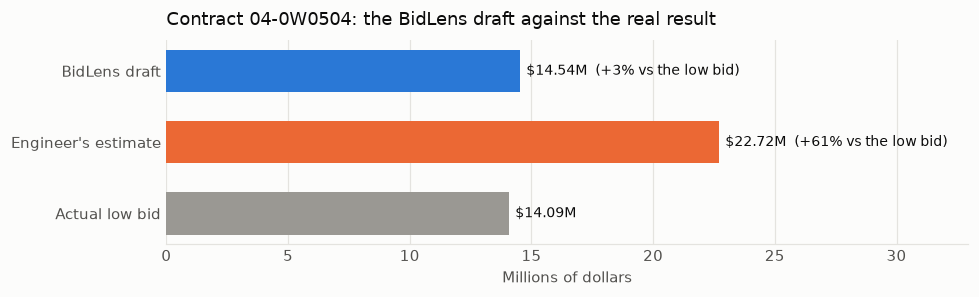

In [7]:
fig = s.chart_draft(s.draft_check())
s.save(fig, "draft_vs_result", s.S21)
plt.show()

## Save

This adds the charts above to `outputs/20_extraction_round2/` and `outputs/21_app/`. To recompute: `uv run python -m bidlens.documents.extract 04-0W0504 --mode combined` (about an hour, needs Ollama with both models), then `uv run python -m bidlens.estimate 04-0W0504` for the draft.

In [8]:
s.note_in_readme(s.S20, "07_document_extraction.ipynb")
s.note_in_readme(s.S21, "07_document_extraction.ipynb")
sorted(p.name for d in (s.S20, s.S21) for p in d.glob("nb_*.png"))

['nb_draft_vs_result.png', 'nb_extraction_runs.png', 'nb_recall_by_topic.png']